<a href="https://colab.research.google.com/github/juanfercaicedo/AprendizajeAutomaticoInicial/blob/main/Deber/VideoExposici%C3%B3n.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aprendizaje No Supervisado

Dimensión de X: (300, 2)


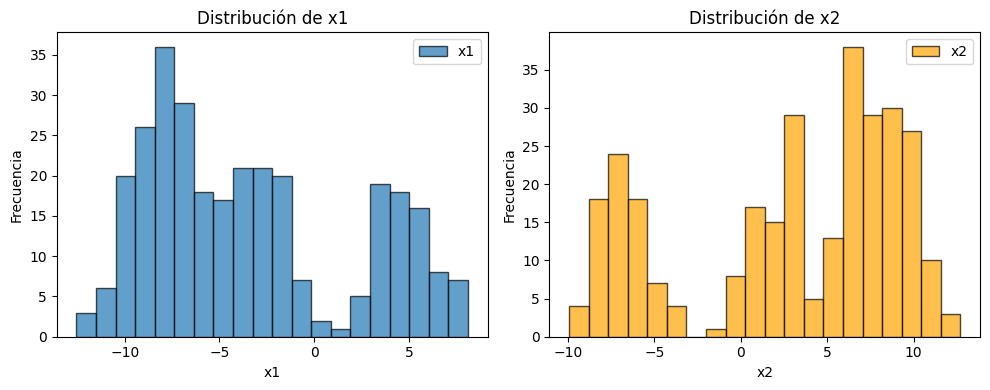

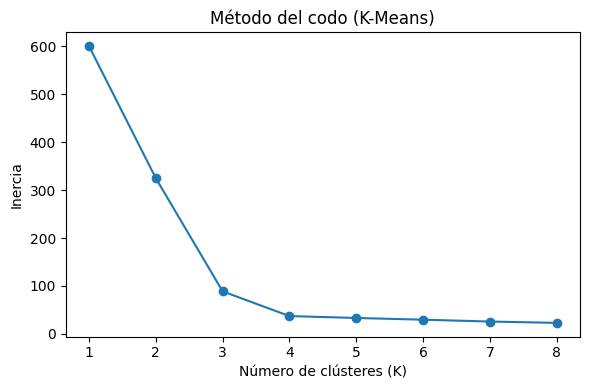

,x1,x2,cluster
0,-9.527369,6.048756,3
1,-10.128948,6.746690,3
2,-1.275380,7.183021,0
3,-7.206149,-5.231944,1
4,-11.895515,5.811393,3
5,-5.593138,-7.120017,1
6,4.899650,2.551146,2
7,-6.260230,-7.725696,1
8,-3.227959,8.735798,0
9,2.852924,2.958000,2


Dimensión de X_pca: (300, 2)
Varianza explicada por componente: [0.52750083 0.47249917]
Varianza acumulada: 1.0


,PC1,PC2,cluster_kmeans
0,-0.440261,-1.162736,3
1,-0.440495,-1.320072,3
2,0.768106,-0.209687,0
3,-1.405889,0.410882,1
4,-0.777116,-1.446161,3
5,-1.407143,0.834626,1
6,1.055499,1.120324,2
7,-1.562676,0.815430,1
8,0.687152,-0.640166,0
9,0.833244,0.806487,2


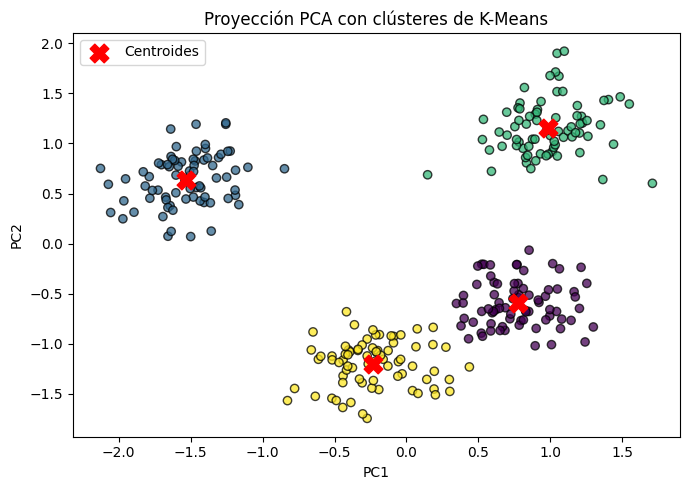

In [1]:
# Paquetes necesarios
import numpy as np  # Para operaciones numéricas
import pandas as pd  # Para manejo de datos estructurados
import matplotlib.pyplot as plt  # Para visualización de datos
from sklearn.datasets import make_blobs  # Para generar datos sintéticos agrupados
from sklearn.preprocessing import StandardScaler  # Para estandarizar variables
from sklearn.cluster import KMeans  # Para agrupamiento no supervisado
from sklearn.decomposition import PCA  # Para reducción de dimensionalidad

# Generamos los datos con make_blobs (sin usar y_true para entrenar los modelos)
X, y_true = make_blobs(n_samples=300, centers=4, cluster_std=1.5, random_state=42)

columnas = ['x1', 'x2']
df = pd.DataFrame(X, columns=columnas)

print('Dimensión de X:', X.shape)
df.head(10)

# Distribución de las dos variables antes de aplicar K-Means o PCA
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(df['x1'], bins=20, alpha=0.7, edgecolor='black', label='x1')
plt.title('Distribución de x1')
plt.xlabel('x1')
plt.ylabel('Frecuencia')
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(df['x2'], bins=20, alpha=0.7, edgecolor='black', label='x2', color='orange')
plt.title('Distribución de x2')
plt.xlabel('x2')
plt.ylabel('Frecuencia')
plt.legend()

plt.tight_layout()
plt.show()

# Escalamos las características con StandardScaler
escalador = StandardScaler()
X_scaled = escalador.fit_transform(X)

df_scaled = pd.DataFrame(X_scaled, columns=columnas)
df_scaled.head(5)

# Evaluamos la inercia para distintos valores de K (método del codo)
inercias = []
valores_k = range(1, 9)

for k in valores_k:
    km_temp = KMeans(n_clusters=k, n_init=10, random_state=42)
    km_temp.fit(X_scaled)
    inercias.append(km_temp.inertia_)

plt.figure(figsize=(6, 4))
plt.plot(list(valores_k), inercias, marker='o')
plt.title('Método del codo (K-Means)')
plt.xlabel('Número de clústeres (K)')
plt.ylabel('Inercia')
plt.tight_layout()
plt.show()

# Entrenamos K-Means con K = 4 y asignamos cada observación a su clúster
modelo_kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
modelo_kmeans.fit(X_scaled)

etiquetas_cluster = modelo_kmeans.predict(X_scaled)

df_clusters = df.copy()
df_clusters['cluster'] = etiquetas_cluster
display(df_clusters.head(10))

# Aplicamos PCA para analizar las componentes principales y la varianza explicada
modelo_pca = PCA(n_components=2, random_state=42)
X_pca = modelo_pca.fit_transform(X_scaled)

print('Dimensión de X_pca:', X_pca.shape)
print('Varianza explicada por componente:', modelo_pca.explained_variance_ratio_)
print('Varianza acumulada:', modelo_pca.explained_variance_ratio_.sum())

df_pca = pd.DataFrame(X_pca, columns=['PC1', 'PC2'])
df_pca['cluster_kmeans'] = etiquetas_cluster
display(df_pca.head(10))

# Proyectamos los centroides de K-Means al espacio de las componentes principales
centroides_pca = modelo_pca.transform(modelo_kmeans.cluster_centers_)

plt.figure(figsize=(7, 5))
plt.scatter(df_pca['PC1'], df_pca['PC2'], c=df_pca['cluster_kmeans'], alpha=0.75, edgecolor='black')
plt.scatter(centroides_pca[:, 0], centroides_pca[:, 1], marker='X', s=180, color='red', label='Centroides')
plt.title('Proyección PCA con clústeres de K-Means')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.tight_layout()
plt.show()